# UAS 1: Web Structure Mining — Crawling, Link Graph & PageRank

**Mata Kuliah:** Penambangan & Pencarian Web (PPW)  
**Program Studi:** Teknik Informatika, Universitas Trunojoyo Madura  
**Nama:** Muhammad Ilham Adila Almafaz  
**NIM:** 230411100113 (23-113)

---

### 📌 Deskripsi Proyek
Proyek ini membangun sistem **Web Structure Mining** end-to-end yang:
1. **Crawling** halaman web dari sebuah domain (contoh: `trunojoyo.ac.id`) secara rekursif.
2. **Mengekstraksi hyperlink** dari setiap halaman yang dikunjungi, lalu mengikuti link tersebut untuk membangun **graf berarah (*Directed Graph*)**.
3. **Menghitung PageRank** untuk menentukan halaman mana yang paling penting/berprestise.
4. **Memvisualisasikan** struktur link dalam bentuk **Citation Graph** interaktif (mirip ScienceDirect).
5. **Menampilkan 10 halaman web dengan PageRank tertinggi.**

### 📦 Alur Kerja
```
Crawl Halaman Web → Ekstraksi Hyperlink → Bangun Graf Berarah
     → Hitung PageRank → Visualisasi Citation Graph → Top-10 Ranking
```

---

## 0. Instalasi & Import Library

In [1]:
# Jalankan sekali untuk instalasi library yang diperlukan
!pip install requests beautifulsoup4 networkx matplotlib pandas pyvis


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin, urlparse
from collections import deque
import time
import json
import os

import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

print("Semua library berhasil dimuat!")

Semua library berhasil dimuat!


---
## 1. Web Crawler & Link Extractor

Crawler ini menggunakan teknik **Breadth-First Search (BFS)**:
1. Mulai dari URL awal (*seed URL*).
2. Kunjungi halaman, ekstraksi semua hyperlink `<a href="...">` di dalamnya.
3. Filter link yang relevan (misal: masih dalam domain yang sama atau domain tertentu).
4. Masukkan link baru ke antrian (*queue*), lalu lanjutkan mengunjungi link berikutnya.
5. Ulangi hingga mencapai batas kedalaman atau jumlah halaman yang ditentukan.

In [3]:
class WebCrawler:
    """Web Crawler BFS untuk mengekstrak graf hyperlink antar halaman."""
    
    def __init__(self, seed_url, max_pages=50, delay=1.0, allowed_domains=None):
        """
        Parameters:
        -----------
        seed_url : str
            URL awal untuk memulai crawling.
        max_pages : int
            Jumlah maksimal halaman yang akan dikunjungi.
        delay : float
            Jeda antar request (detik) agar tidak membebani server.
        allowed_domains : list or None
            Daftar domain yang diizinkan untuk di-crawl.
            Jika None, hanya domain dari seed_url yang diizinkan.
        """
        self.seed_url = seed_url
        self.max_pages = max_pages
        self.delay = delay
        
        parsed = urlparse(seed_url)
        self.seed_domain = parsed.netloc
        self.allowed_domains = allowed_domains or [self.seed_domain]
        
        self.visited = set()       # URL yang sudah dikunjungi
        self.edges = []            # List of (source_url, target_url)
        self.page_titles = {}      # {url: title}
        self.failed_urls = []      # URL yang gagal diakses
        
        self.headers = {
            'User-Agent': 'Mozilla/5.0 (PPW-UTM-Bot/1.0; Educational Purpose)'
        }
    
    def _normalize_url(self, url):
        """Normalisasi URL: hapus fragment (#), trailing slash, dan parameter kosong."""
        parsed = urlparse(url)
        # Hilangkan fragment (#section) dan standardisasi
        normalized = f"{parsed.scheme}://{parsed.netloc}{parsed.path}"
        # Hapus trailing slash ganda
        normalized = normalized.rstrip('/')
        return normalized
    
    def _is_valid_url(self, url):
        """Cek apakah URL valid untuk di-crawl."""
        try:
            parsed = urlparse(url)
            # Harus http/https
            if parsed.scheme not in ('http', 'https'):
                return False
            # Harus dalam domain yang diizinkan
            if not any(d in parsed.netloc for d in self.allowed_domains):
                return False
            # Skip file non-HTML
            skip_ext = ('.pdf', '.jpg', '.jpeg', '.png', '.gif', '.svg',
                        '.css', '.js', '.zip', '.doc', '.docx', '.xls',
                        '.xlsx', '.ppt', '.pptx', '.mp3', '.mp4', '.avi')
            if parsed.path.lower().endswith(skip_ext):
                return False
            return True
        except:
            return False
    
    def _extract_links(self, url, html):
        """Ekstraksi semua hyperlink dari sebuah halaman HTML."""
        soup = BeautifulSoup(html, 'html.parser')
        
        # Ambil judul halaman
        title_tag = soup.find('title')
        title = title_tag.get_text(strip=True) if title_tag else url
        self.page_titles[url] = title
        
        # Ekstraksi semua <a href="...">
        links = set()
        for a_tag in soup.find_all('a', href=True):
            href = a_tag['href'].strip()
            # Resolusi URL relatif menjadi absolut
            full_url = urljoin(url, href)
            normalized = self._normalize_url(full_url)
            
            if self._is_valid_url(normalized) and normalized != url:
                links.add(normalized)
        
        return links
    
    def crawl(self):
        """Jalankan proses crawling BFS."""
        queue = deque([self._normalize_url(self.seed_url)])
        
        print(f"🕷️  Memulai crawling dari: {self.seed_url}")
        print(f"   Domain: {self.allowed_domains}")
        print(f"   Maks halaman: {self.max_pages}")
        print(f"   Jeda antar request: {self.delay}s")
        print("-" * 60)
        
        while queue and len(self.visited) < self.max_pages:
            current_url = queue.popleft()
            
            if current_url in self.visited:
                continue
            
            try:
                response = requests.get(current_url, headers=self.headers, timeout=10)
                response.raise_for_status()
                
                # Pastikan response adalah HTML
                content_type = response.headers.get('Content-Type', '')
                if 'text/html' not in content_type:
                    continue
                
                self.visited.add(current_url)
                page_num = len(self.visited)
                
                # Ekstraksi link
                found_links = self._extract_links(current_url, response.text)
                
                # Simpan edges (current -> target)
                for target in found_links:
                    self.edges.append((current_url, target))
                    if target not in self.visited:
                        queue.append(target)
                
                title = self.page_titles.get(current_url, current_url)
                print(f"  [{page_num:3d}/{self.max_pages}] ✅ {current_url[:70]}")
                print(f"            Judul: {title[:50]}")
                print(f"            Link ditemukan: {len(found_links)}")
                
                time.sleep(self.delay)
                
            except Exception as e:
                self.failed_urls.append((current_url, str(e)))
                print(f"  [---] {current_url[:70]} -> {str(e)[:40]}")
        
        print("-" * 60)
        print(f"\nCrawling selesai!")
        print(f"   Halaman berhasil dikunjungi : {len(self.visited)}")
        print(f"   Total link (edges) ditemukan: {len(self.edges)}")
        print(f"   Halaman gagal diakses       : {len(self.failed_urls)}")
        
        return self.visited, self.edges

### 1.1 Menjalankan Crawler

Ubah `SEED_URL` dan `MAX_PAGES` sesuai kebutuhan.  
Untuk demo, kita mulai dari halaman utama **Universitas Trunojoyo Madura**.

In [4]:
SEED_URL = 'https://www.trunojoyo.ac.id'  # URL awal
MAX_PAGES = 10                            # Jumlah maks halaman yang di-crawl
DELAY = 1.0                               # Jeda antar request (detik)

# Domain yang diizinkan (bisa ditambah subdomain)
ALLOWED_DOMAINS = ['trunojoyo.ac.id']

# Jalankan Crawler
crawler = WebCrawler(
    seed_url=SEED_URL,
    max_pages=MAX_PAGES,
    delay=DELAY,
    allowed_domains=ALLOWED_DOMAINS
)

visited_pages, all_edges = crawler.crawl()

🕷️  Memulai crawling dari: https://www.trunojoyo.ac.id
   Domain: ['trunojoyo.ac.id']
   Maks halaman: 10
   Jeda antar request: 1.0s
------------------------------------------------------------
  [  1/10] ✅ https://www.trunojoyo.ac.id
            Judul: UTM Official – Unggul, Tangguh, Mandiri
            Link ditemukan: 48
  [---] https://lpmpp.trunojoyo.ac.id -> HTTPSConnectionPool(host='lpmpp.trunojoy
  [---] https://asrama.trunojoyo.ac.id -> 403 Client Error: Forbidden for url: htt
  [  2/10] ✅ https://www2.trunojoyo.ac.id/dokumen-sumber-daya-manusia
            Judul: Dokumen Sumber Daya Manusia – UTM Official
            Link ditemukan: 43
  [  3/10] ✅ https://www2.trunojoyo.ac.id/category/headlines
            Judul: Headlines – UTM Official
            Link ditemukan: 114
  [---] https://fip.trunojoyo.ac.id -> HTTPSConnectionPool(host='fip.trunojoyo.
  [  4/10] ✅ https://fk.trunojoyo.ac.id
            Judul: Fakultas Kedokteran Universitas Trunodjoyo Madura
            Link dit

---
## 2. Membangun Graf Berarah (*Directed Graph*) dari Hasil Crawling

Setiap halaman web menjadi **node (simpul)**, dan setiap hyperlink menjadi **edge berarah (busur)**:
- Halaman A memiliki link ke Halaman B → Edge: $A \to B$

In [5]:
# Filter edges: hanya simpul yang benar-benar dikunjungi
filtered_edges = [(s, t) for s, t in all_edges if s in visited_pages and t in visited_pages]

# Buat DiGraph
G = nx.DiGraph()
G.add_nodes_from(visited_pages)
G.add_edges_from(filtered_edges)

# Hapus self-loop (link ke diri sendiri)
G.remove_edges_from(nx.selfloop_edges(G))

print("=" * 55)
print("       STATISTIK GRAF HYPERLINK HASIL CRAWLING")
print("=" * 55)
print(f"  Jumlah Simpul (Halaman)     : {G.number_of_nodes()}")
print(f"  Jumlah Busur (Hyperlink)    : {G.number_of_edges()}")
print(f"  Density Graf                : {nx.density(G):.4f}")

if nx.is_weakly_connected(G):
    print(f"  Weakly Connected            : Ya")
else:
    num_components = nx.number_weakly_connected_components(G)
    print(f"  Weakly Connected Components : {num_components}")

print(f"\n  Rata-rata In-Degree  : {np.mean([d for _, d in G.in_degree()]):.2f}")
print(f"  Rata-rata Out-Degree : {np.mean([d for _, d in G.out_degree()]):.2f}")

# ============================================================
# FUNGSI HELPER: NAMA HALAMAN DESKRIPTIF (Bukan hanya '/')
# ============================================================
def get_page_name(url, page_titles=None, max_len=30):
    """
    Menghasilkan nama halaman yang informatif dan manusiawi:
    1. Menggunakan tag <title> yang sudah dibersihkan.
    2. Menampilkan subdomain (misal: '[ft] Beranda', '[lppm] Beranda').
    3. Menampilkan path spesifik (misal: '/visimisi').
    """
    parsed = urlparse(url)
    
    # 1. Prioritaskan Judul Halaman (tag <title>) jika valid
    if page_titles and url in page_titles:
        title = page_titles[url].strip()
        for suffix in ['- Universitas Trunojoyo Madura', '| Universitas Trunojoyo Madura', '- UTM', '| UTM']:
            if suffix in title:
                title = title.replace(suffix, '').strip()
        if title and title != '-' and title != url and not title.startswith('http'):
            return title[:max_len]
            
    # 2. Jika tidak ada judul, periksa subdomain dan path
    netloc = parsed.netloc.replace('www.', '')
    subdomain = netloc.replace('.trunojoyo.ac.id', '').replace('trunojoyo.ac.id', '')
    path = parsed.path.strip('/')
    
    if path:
        last_slug = path.split('/')[-1]
        if subdomain:
            return f"[{subdomain}] /{last_slug}"[:max_len]
        return f"/{last_slug}"[:max_len]
    else:
        if subdomain:
            return f"[{subdomain}] Beranda"[:max_len]
        return "Beranda Utama (UTM)"



       STATISTIK GRAF HYPERLINK HASIL CRAWLING
  Jumlah Simpul (Halaman)     : 10
  Jumlah Busur (Hyperlink)    : 43
  Density Graf                : 0.4778
  Weakly Connected            : Ya

  Rata-rata In-Degree  : 4.30
  Rata-rata Out-Degree : 4.30


In [6]:
# ============================================================
# MATRIKS ADJASENSI (Tampilkan 10x10 Pertama)
# ============================================================
nodes_list = sorted(G.nodes())
show_n = min(10, len(nodes_list))
subset_nodes = nodes_list[:show_n]

# Buat label deskriptif
short_labels = {url: get_page_name(url, crawler.page_titles, max_len=20) for url in subset_nodes}

adj_sub = nx.to_pandas_adjacency(G, nodelist=subset_nodes, dtype=int)
adj_sub.index = [short_labels[n] for n in subset_nodes]
adj_sub.columns = [short_labels[n] for n in subset_nodes]

print(f"=== MATRIKS ADJASENSI ({show_n}x{show_n} pertama) ===")
print(adj_sub)



=== MATRIKS ADJASENSI (10x10 pertama) ===
                      Fakultas Kedokteran   Bot Detection  \
Fakultas Kedokteran                      0              0   
Bot Detection                            0              0   
Sistem Informasi MBK                     0              0   
PASCASARJANA Officia                     0              0   
Seleksi Mandiri Masu                     0              0   
UTM Official – Unggu                     1              1   
Headlines – UTM Offi                     1              1   
Data Penelitian – UT                     1              1   
Dokumen Sumber Daya                      1              1   
Sejarah – UTM Offici                     1              1   

                      Sistem Informasi MBK  PASCASARJANA Officia  \
Fakultas Kedokteran                      1                     0   
Bot Detection                            0                     0   
Sistem Informasi MBK                     0                     0   
PASCASARJANA O

---
## 3. Perhitungan PageRank

### Rumus PageRank:
$$PR(v) = \frac{1 - d}{N} + d \sum_{u \to v} \frac{PR(u)}{D_{out}(u)}$$

- $d = 0{,}85$ (damping factor)
- $N$ = jumlah total halaman
- $u \to v$ = halaman $u$ memiliki link menuju halaman $v$
- $D_{out}(u)$ = jumlah link keluar dari halaman $u$

In [7]:

d = 0.85
N = G.number_of_nodes()
threshold = 1e-6
max_iter = 100

# Inisialisasi PR = 1/N
PR = {node: 1/N for node in G.nodes()}

print(f"Damping Factor (d) : {d}")
print(f"Jumlah Node (N)    : {N}")
print(f"Threshold          : {threshold}")
print(f"{'Iterasi':>8} | {'Selisih Maks':>15} | Status")
print("-" * 45)

konvergen_iter = None
for it in range(1, max_iter + 1):
    PR_baru = {}
    for v in G.nodes():
        sigma = 0
        for u in G.predecessors(v):
            out_deg = G.out_degree(u)
            if out_deg > 0:
                sigma += PR[u] / out_deg
        PR_baru[v] = (1 - d) / N + d * sigma
    
    max_diff = max(abs(PR_baru[n] - PR[n]) for n in G.nodes())
    PR = PR_baru
    
    status = "✅ KONVERGEN!" if max_diff < threshold else ""
    print(f"{it:>8} | {max_diff:>15.10f} | {status}")
    
    if max_diff < threshold:
        konvergen_iter = it
        break

if konvergen_iter:
    print(f"\n✅ PageRank konvergen di iterasi ke-{konvergen_iter}")
else:
    print(f"\n Belum konvergen setelah {max_iter} iterasi")

print(f"Total skor PR: {sum(PR.values()):.6f} (harus mendekati 1.0)")

Damping Factor (d) : 0.85
Jumlah Node (N)    : 10
Threshold          : 1e-06
 Iterasi |    Selisih Maks | Status
---------------------------------------------
       1 |    0.0755555556 | 
       2 |    0.0470377604 | 
       3 |    0.0243061529 | 
       4 |    0.0114799335 | 
       5 |    0.0061052752 | 
       6 |    0.0030995610 | 
       7 |    0.0015871524 | 
       8 |    0.0008134875 | 
       9 |    0.0004163817 | 
      10 |    0.0002132363 | 
      11 |    0.0001091914 | 
      12 |    0.0000559127 | 
      13 |    0.0000286312 | 
      14 |    0.0000146611 | 
      15 |    0.0000075075 | 
      16 |    0.0000038443 | 
      17 |    0.0000019686 | 
      18 |    0.0000010080 | 
      19 |    0.0000005162 | ✅ KONVERGEN!

✅ PageRank konvergen di iterasi ke-19
Total skor PR: 0.331802 (harus mendekati 1.0)


In [8]:
pr_nx = nx.pagerank(G, alpha=0.85)

# Bandingkan
print("=== VERIFIKASI: Manual vs NetworkX (5 node teratas) ===")
top5 = sorted(pr_nx.items(), key=lambda x: x[1], reverse=True)[:5]
for url, score in top5:
    manual_score = PR.get(url, 0)
    title = crawler.page_titles.get(url, url)[:40]
    print(f"  {title:<40} | Manual: {manual_score:.6f} | NX: {score:.6f}")

=== VERIFIKASI: Manual vs NetworkX (5 node teratas) ===
  Sistem Informasi MBKM                    | Manual: 0.056662 | NX: 0.170771
  UTM Official – Unggul, Tangguh, Mandiri  | Manual: 0.049859 | NX: 0.150268
  Fakultas Kedokteran Universitas Trunodjo | Manual: 0.030628 | NX: 0.092308
  Seleksi Mandiri Masuk UTM (SMMUTM) – PMB | Manual: 0.030628 | NX: 0.092308
  Bot Detection                            | Manual: 0.030628 | NX: 0.092308


---
## 4. 🏆 Top-10 Halaman Web dengan PageRank Tertinggi

In [9]:
ranking = sorted(pr_nx.items(), key=lambda x: x[1], reverse=True)

top10_data = []
for rank, (url, score) in enumerate(ranking[:10], 1):
    title = crawler.page_titles.get(url, '-')
    in_deg = G.in_degree(url)
    out_deg = G.out_degree(url)
    top10_data.append({
        'Rank': rank,
        'Judul Halaman': title[:60],
        'URL': url[:70],
        'PageRank': round(score, 6),
        'In-Degree': in_deg,
        'Out-Degree': out_deg
    })

df_top10 = pd.DataFrame(top10_data)
print("=" * 80)
print("     🏆 TOP-10 HALAMAN WEB DENGAN PAGERANK TERTINGGI")
print("=" * 80)
print(df_top10.to_string(index=False))

# Node tertinggi
best_url = ranking[0][0]
best_title = crawler.page_titles.get(best_url, best_url)
print(f"\n🥇 Halaman PALING PENTING: {best_title}")
print(f"   URL: {best_url}")
print(f"   PageRank: {ranking[0][1]:.6f}")

     🏆 TOP-10 HALAMAN WEB DENGAN PAGERANK TERTINGGI
 Rank                                     Judul Halaman                                                          URL  PageRank  In-Degree  Out-Degree
    1                             Sistem Informasi MBKM                                 https://mbkm.trunojoyo.ac.id  0.170771          6           0
    2           UTM Official – Unggul, Tangguh, Mandiri                                  https://www.trunojoyo.ac.id  0.150268          4           9
    3 Fakultas Kedokteran Universitas Trunodjoyo Madura                                   https://fk.trunojoyo.ac.id  0.092308          5           1
    4      Seleksi Mandiri Masuk UTM (SMMUTM) – PMB UTM https://pmb.trunojoyo.ac.id/seleksi-mandiri-masuk-utm-smmutm  0.092308          5           0
    5                                     Bot Detection                                  https://hki.trunojoyo.ac.id  0.092308          5           0
    6                             PASCASARJANA O

C:\Users\ASUS\AppData\Local\Temp\ipykernel_17820\571082641.py:18: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
c:\Users\ASUS\Documents\SEMESTER 7\PPW\enWebmining\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


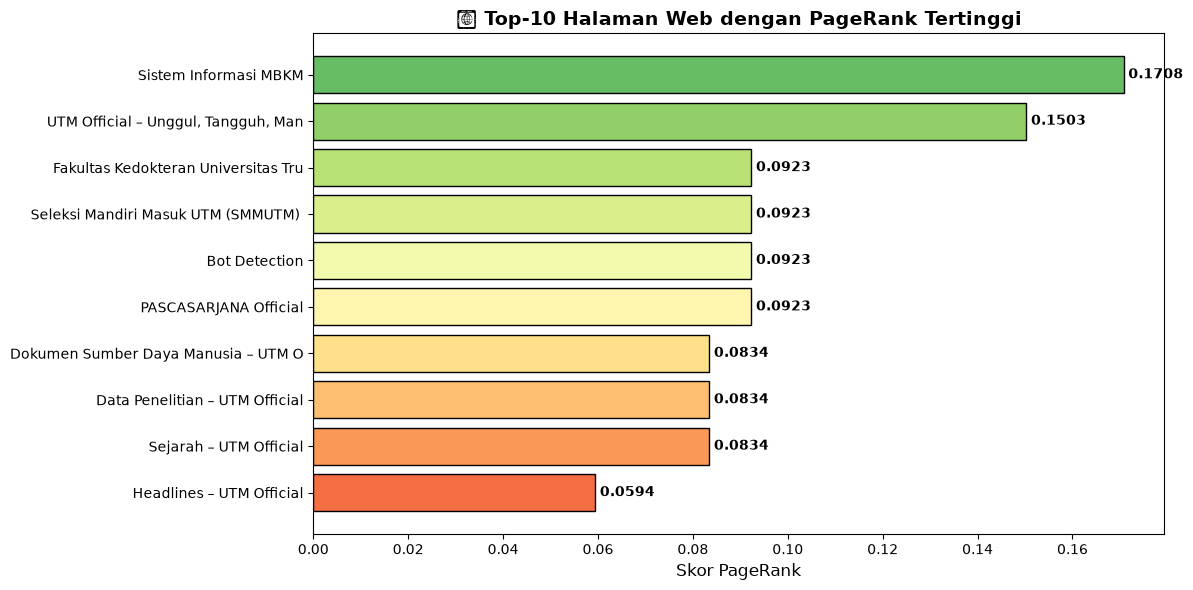

In [10]:
fig, ax = plt.subplots(figsize=(12, 6))

labels = [crawler.page_titles.get(url, url)[:35] for url, _ in ranking[:10]]
scores = [score for _, score in ranking[:10]]
colors = plt.cm.RdYlGn_r(np.linspace(0.2, 0.8, 10))

bars = ax.barh(range(9, -1, -1), scores, color=colors, edgecolor='black')
ax.set_yticks(range(9, -1, -1))
ax.set_yticklabels(labels, fontsize=10)
ax.set_xlabel('Skor PageRank', fontsize=12)
ax.set_title('🏆 Top-10 Halaman Web dengan PageRank Tertinggi', fontsize=14, fontweight='bold')

# Tampilkan nilai di ujung bar
for i, (bar, score) in enumerate(zip(bars, scores)):
    ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
            f'{score:.4f}', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

---
## 5. Visualisasi Graf Hyperlink (Citation Graph Style)

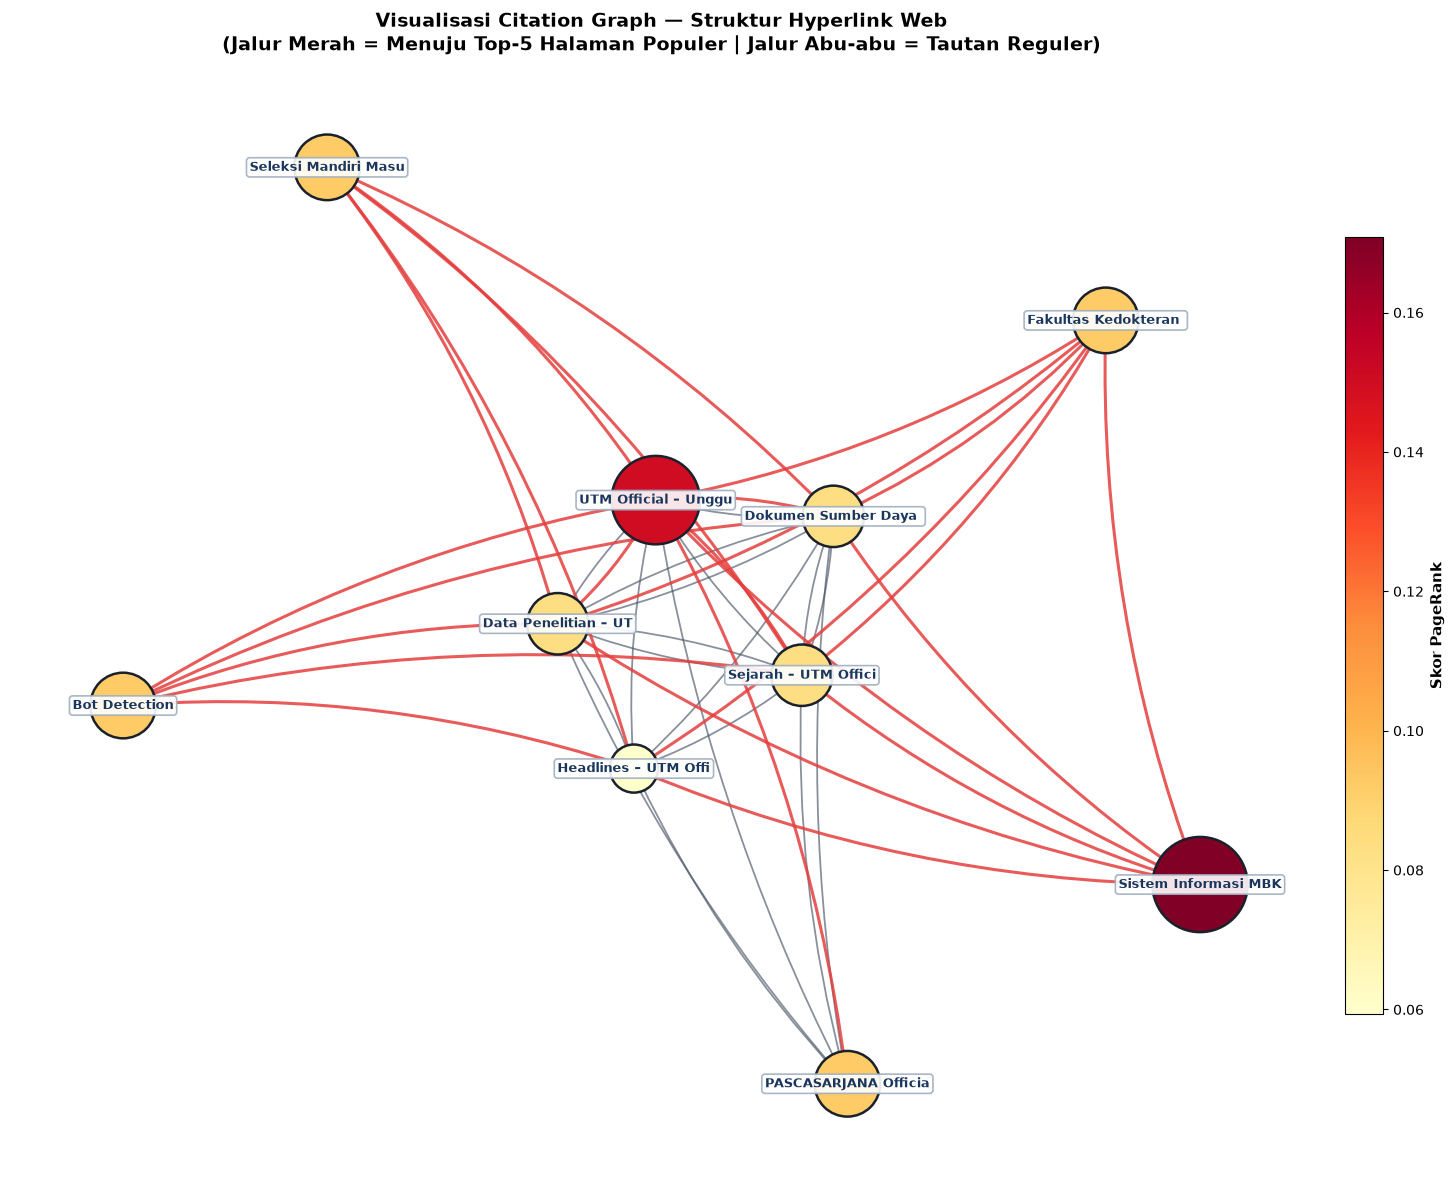

In [11]:
# ============================================================
# VISUALISASI STATIK GRAF DENGAN MATPLOTLIB (JALUR JELAS)
# ============================================================
plt.figure(figsize=(16, 12))

# Layout: spring layout dengan jarak antar node lebih renggang (k=2.5)
pos = nx.spring_layout(G, k=2.5, iterations=80, seed=42)

# Ukuran node proporsional terhadap PageRank
pr_values = [pr_nx[n] for n in G.nodes()]
max_pr = max(pr_values) if pr_values else 1
min_pr = min(pr_values) if pr_values else 0
pr_denom = (max_pr - min_pr) if (max_pr - min_pr) > 0 else 1

node_sizes = [1200 + 3500 * ((pr_nx[n] - min_pr) / pr_denom) for n in G.nodes()]
node_colors = [pr_nx[n] for n in G.nodes()]

# Pisahkan edges: Edges menuju Top-5 (highlight) vs Edges biasa
top5_set = set([url for url, _ in ranking[:5]])
highlight_edges = [(u, v) for u, v in G.edges() if v in top5_set]
regular_edges = [(u, v) for u, v in G.edges() if v not in top5_set]

# 1. Gambar Edges Reguler (Warna abu-abu gelap, alpha=0.65, width=1.3)
nx.draw_networkx_edges(
    G, pos,
    edgelist=regular_edges,
    alpha=0.65,
    edge_color='#4a5568',
    width=1.3,
    arrows=True,
    arrowsize=16,
    arrowstyle='-|>',
    connectionstyle='arc3,rad=0.08'
)

# 2. Gambar Edges Menuju Halaman Populer (Top-5) - Warna Merah/Coral, Tebal
nx.draw_networkx_edges(
    G, pos,
    edgelist=highlight_edges,
    alpha=0.85,
    edge_color='#e53e3e',
    width=2.2,
    arrows=True,
    arrowsize=20,
    arrowstyle='-|>',
    connectionstyle='arc3,rad=0.1'
)

# 3. Gambar Nodes dengan batas hitam tegas
nodes_draw = nx.draw_networkx_nodes(
    G, pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap=cm.YlOrRd,
    edgecolors='#1a202c',
    linewidths=1.8
)

# 4. Label Deskriptif & Mudah Dibaca (dengan Bounding Box Putih)
top10_urls = [url for url, _ in ranking[:10]]
top_labels = {url: get_page_name(url, crawler.page_titles, max_len=20) for url in top10_urls}

# Gambar label dengan box agar teks tidak tertutup garis jalur
for node, label in top_labels.items():
    x, y = pos[node]
    plt.text(
        x, y,
        label,
        fontsize=9,
        fontweight='bold',
        color='#1a365d',
        ha='center',
        va='center',
        bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#a0aec0', alpha=0.9, lw=1.2)
    )

# Colorbar
cbar = plt.colorbar(nodes_draw, shrink=0.7, pad=0.02)
cbar.set_label('Skor PageRank', fontsize=11, fontweight='bold')

plt.title('Visualisasi Citation Graph — Struktur Hyperlink Web\n'
          '(Jalur Merah = Menuju Top-5 Halaman Populer | Jalur Abu-abu = Tautan Reguler)',
          fontsize=14, fontweight='bold', pad=15)
plt.axis('off')
plt.tight_layout()
plt.show()



---
## 6. Visualisasi Interaktif Citation Graph (HTML)

Menggunakan library **`pyvis`** untuk menghasilkan file HTML interaktif yang dapat di-deploy ke server lab. Node dapat di-*drag*, di-*zoom*, dan di-*hover* untuk melihat informasi detail.

In [12]:
try:
    from pyvis.network import Network
    from IPython.display import display, IFrame

    # Inisialisasi graf interaktif
    net = Network(height='750px', width='100%', directed=True,
                  bgcolor='#1a1a2e', font_color='white',
                  cdn_resources='remote')

    # Konfigurasi fisika (Force-Directed) agar node menyebar rapi
    net.barnes_hut(gravity=-4000, central_gravity=0.3,
                   spring_length=180, spring_strength=0.03, damping=0.09)

    max_pr_val = max(pr_nx.values()) if pr_nx else 1
    min_pr_val = min(pr_nx.values()) if pr_nx else 0
    denom = (max_pr_val - min_pr_val) if (max_pr_val - min_pr_val) > 0 else 1

    # Tambahkan Simpul (Nodes)
    for node in G.nodes():
        pr_val = pr_nx[node]
        title = crawler.page_titles.get(node, node)
        label = get_page_name(node, crawler.page_titles, max_len=22)

        norm_size = (pr_val - min_pr_val) / denom
        size = 18 + norm_size * 55

        # Gradasi warna: Biru Muda -> Kuning -> Oranye -> Merah Menyala
        r = int(50 + norm_size * 205)
        g = int(180 - norm_size * 120)
        b = int(240 - norm_size * 200)
        color = f'rgb({r}, {g}, {b})'

        rank_pos = [i + 1 for i, (u, _) in enumerate(ranking) if u == node]
        rank_str = f"Rank #{rank_pos[0]}" if rank_pos else ""

        hover_text = (
            f"<div style='font-family: Arial, sans-serif; padding: 4px;'>"
            f"<b style='font-size: 13px; color: #f6e05e;'>{title}</b><br>"
            f"<span style='font-size: 11px; color: #cbd5e0;'>{node}</span><br>"
            f"<hr style='border: 0; border-top: 1px solid #4a5568; margin: 6px 0;'>"
            f"<b>🏆 PageRank:</b> <span style='color: #68d391;'>{pr_val:.6f}</span> ({rank_str})<br>"
            f"<b>📥 In-Degree (Tautan Masuk):</b> {G.in_degree(node)}<br>"
            f"<b>📤 Out-Degree (Tautan Keluar):</b> {G.out_degree(node)}"
            f"</div>"
        )

        net.add_node(node, label=label, title=hover_text,
                     size=size, color=color,
                     borderWidth=2,
                     borderWidthSelected=4)

    # Tambahkan Sisi (Edges) - Jalur Jelas, Tebal, dan Berpanah Tegas
    for source, target in G.edges():
        is_to_top = target in [u for u, _ in ranking[:5]]
        edge_color = 'rgba(239, 68, 68, 0.85)' if is_to_top else 'rgba(160, 174, 192, 0.65)'
        edge_width = 2.2 if is_to_top else 1.4

        net.add_edge(
            source, target,
            color={'color': edge_color, 'highlight': '#ff4757', 'hover': '#38bdf8'},
            arrows={'to': {'enabled': True, 'scaleFactor': 0.8}},
            width=edge_width,
            smooth={'type': 'curvedCW', 'roundness': 0.12}
        )

    # Simpan HTML dengan encoding='utf-8' eksplisit (MENCEGAH ERROR UnicodeEncodeError Windows)
    output_html = 'citation_graph.html'
    html_content = net.generate_html()
    with open(output_html, 'w', encoding='utf-8') as f:
        f.write(html_content)

    print(f"✅ Visualisasi interaktif Citation Graph berhasil disimpan ke: {output_html}")
    print("   Jalur hyperlink dibuat jelas, tebal, dan berpanah.")
    print("   Menampilkan preview di bawah:")

    # Tampilkan preview iframe di notebook
    display(IFrame(src=output_html, width='100%', height='750px'))

except ImportError:
    print("⚠️ Library pyvis belum terinstall.")
    print("   Jalankan: pip install pyvis")
    print("   Visualisasi statik matplotlib di atas tetap tersedia.")



✅ Visualisasi interaktif Citation Graph berhasil disimpan ke: citation_graph.html
   Jalur hyperlink dibuat jelas, tebal, dan berpanah.
   Menampilkan preview di bawah:


---
## 7. Analisis Sentralitas Tambahan

In [13]:
# ============================================================
# ANALISIS SENTRALITAS LENGKAP (Top-10)
# ============================================================

# Hitung berbagai metrik sentralitas
deg_centrality = nx.degree_centrality(G)
in_deg_centrality = nx.in_degree_centrality(G)
out_deg_centrality = nx.out_degree_centrality(G)

# Betweenness Centrality
betw_centrality = nx.betweenness_centrality(G)

# Bangun tabel perbandingan sentralitas (Top-10 berdasarkan PageRank)
centrality_data = []
for rank, (url, pr_score) in enumerate(ranking[:10], 1):
    page_name = get_page_name(url, crawler.page_titles, max_len=30)
    parsed = urlparse(url)
    short_url = (parsed.netloc.replace('www.', '') + parsed.path)[:35]
    
    centrality_data.append({
        'Rank': rank,
        'Nama Halaman': page_name,
        'URL Ringkas': short_url,
        'PageRank': round(pr_score, 4),
        'In-Degree C.': round(in_deg_centrality[url], 4),
        'Out-Degree C.': round(out_deg_centrality[url], 4),
        'Betweenness C.': round(betw_centrality[url], 4)
    })

df_centrality = pd.DataFrame(centrality_data)

print("=== PERBANDINGAN METRIK SENTRALITAS (Top-10 PageRank) ===")
print(df_centrality.to_string(index=False))



=== PERBANDINGAN METRIK SENTRALITAS (Top-10 PageRank) ===
 Rank                   Nama Halaman                         URL Ringkas  PageRank  In-Degree C.  Out-Degree C.  Betweenness C.
    1          Sistem Informasi MBKM                mbkm.trunojoyo.ac.id    0.1708        0.6667         0.0000          0.0000
    2 UTM Official – Unggul, Tangguh                     trunojoyo.ac.id    0.1503        0.4444         1.0000          0.1528
    3 Fakultas Kedokteran Universita                  fk.trunojoyo.ac.id    0.0923        0.5556         0.1111          0.0000
    4 Seleksi Mandiri Masuk UTM (SMM pmb.trunojoyo.ac.id/seleksi-mandiri    0.0923        0.5556         0.0000          0.0000
    5                  Bot Detection                 hki.trunojoyo.ac.id    0.0923        0.5556         0.0000          0.0000
    6          PASCASARJANA Official               pasca.trunojoyo.ac.id    0.0923        0.5556         0.1111          0.0035
    7 Dokumen Sumber Daya Manusia –  www2.trun

---
## 8. Ekspor Data untuk Deployment ke Server Lab

Data graf dan PageRank diekspor ke format JSON agar dapat digunakan oleh aplikasi web (Flask/FastAPI + D3.js) di server lab.

In [14]:
# ============================================================
# EKSPOR DATA GRAF KE JSON
# ============================================================
output_dir = 'Output'
os.makedirs(output_dir, exist_ok=True)

# 1. Data Node
nodes_data = []
for rank, (url, pr_score) in enumerate(ranking, 1):
    nodes_data.append({
        'id': url,
        'title': crawler.page_titles.get(url, url),
        'path': urlparse(url).path or '/',
        'pagerank': round(pr_score, 8),
        'rank': rank,
        'in_degree': G.in_degree(url),
        'out_degree': G.out_degree(url),
        'betweenness': round(betw_centrality.get(url, 0), 8)
    })

# 2. Data Edge
edges_data = [{'source': s, 'target': t} for s, t in G.edges()]

# 3. Gabungkan dan simpan
graph_export = {
    'metadata': {
        'seed_url': SEED_URL,
        'total_nodes': G.number_of_nodes(),
        'total_edges': G.number_of_edges(),
        'density': round(nx.density(G), 6),
        'damping_factor': d,
        'converged_at_iteration': konvergen_iter
    },
    'nodes': nodes_data,
    'edges': edges_data
}

output_path = os.path.join(output_dir, 'graph_pagerank.json')
with open(output_path, 'w', encoding='utf-8') as f:
    json.dump(graph_export, f, ensure_ascii=False, indent=2)

# 4. Simpan Top-10 sebagai CSV
csv_path = os.path.join(output_dir, 'top10_pagerank.csv')
df_top10.to_csv(csv_path, index=False)

print(f"✅ Data graf diekspor ke: {output_path}")
print(f"✅ Top-10 PageRank CSV  : {csv_path}")
print(f"\n📦 File-file ini siap digunakan untuk deployment ke server lab.")
print(f"   Gunakan Flask/FastAPI + D3.js untuk membangun UI Citation Graph.")

✅ Data graf diekspor ke: Output\graph_pagerank.json
✅ Top-10 PageRank CSV  : Output\top10_pagerank.csv

📦 File-file ini siap digunakan untuk deployment ke server lab.
   Gunakan Flask/FastAPI + D3.js untuk membangun UI Citation Graph.


---
## Ringkasan Proyek

| Tahap | Deskripsi | Output |
| :--- | :--- | :--- |
| **1. Crawling** | BFS crawling dari *seed URL* → kunjungi halaman secara rekursif | Daftar halaman & relasi link |
| **2. Graph Building** | Membangun **Graf Berarah** (*DiGraph*) dari hyperlink | Adjacency Matrix, Statistik Graf |
| **3. PageRank** | Perhitungan iteratif manual + verifikasi NetworkX | Skor PageRank setiap halaman, Iterasi konvergensi |
| **4. Ranking** | Mengurutkan halaman berdasarkan skor PageRank | **Top-10 halaman terpenting** |
| **5. Visualisasi** | Citation Graph statik (Matplotlib) & interaktif (Pyvis HTML) | Grafik & file `citation_graph.html` |
| **6. Analisis** | Sentralitas tambahan (Degree, Betweenness) | Tabel perbandingan metrik |
| **7. Ekspor** | JSON + CSV untuk deployment server lab | `graph_pagerank.json`, `top10_pagerank.csv` |

### Alur Deployment ke Server Lab:
```
graph_pagerank.json → Backend (Flask/FastAPI) → Frontend (D3.js Citation Graph UI)
                    → Deploy ke Server Lab
```